# Mori-Zwanzig on the Lorenz 63 System
## AI INFN Hackathon@Ferrara · 2 December 2026
**Alessandro Gabbana** ([alessandro.gabbana@unife.it](mailto:alessandro.gabbana@unife.it)) · **André Freitas** ([Andre.Freitas@roma2.infn.it](mailto:Andre.Freitas@roma2.infn.it))

---

The **Lorenz 63** system is a canonical example of deterministic chaos:

$$\dot{x} = \sigma(y - x), \qquad \dot{y} = x(\rho - z) - y, \qquad \dot{z} = xy - \beta z$$

with parameters $\sigma = 10$, $\rho = 28$, $\beta = 8/3$.

In this notebook we:
1. Simulate the attractor and generate short trajectory data.
2. Explore the (non-Markovian) one-step maps for each component.
3. **[Exercise]** Apply the Mori–Zwanzig sequential regression framework with Neural Network
   operators to predict the dynamics of a **single chosen component**, treating the other
   two as unresolved.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 1. The Lorenz 63 Attractor

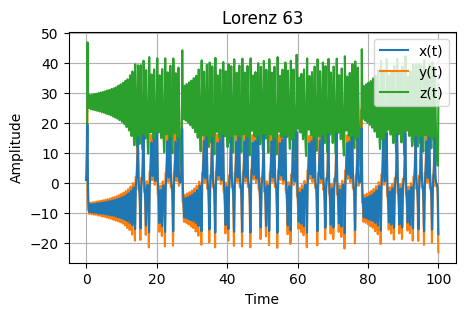

In [2]:
from scipy.integrate import solve_ivp

def lorenz63(t, state, sigma=10.0, rho=28.0, beta=8.0/3):
    x, y, z = state
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return [dx, dy, dz]


# Parameters
sigma = 10.0
rho   = 28.0
beta  = 8.0 / 3
z0    = [1.0, 1.0, 1.0]
t_span = (0, 100)
t_eval = np.linspace(t_span[0], t_span[1], 2001)

solution = solve_ivp(lorenz63, t_span, z0, args=(sigma, rho, beta), t_eval=t_eval)

t = solution.t
x = solution.y[0]
y = solution.y[1]
z = solution.y[2]

plt.figure(figsize=(5, 3))
plt.plot(t, x, label="x(t)", zorder=10)
plt.plot(t, y, label="y(t)")
plt.plot(t, z, label="z(t)")
plt.title('Lorenz 63')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

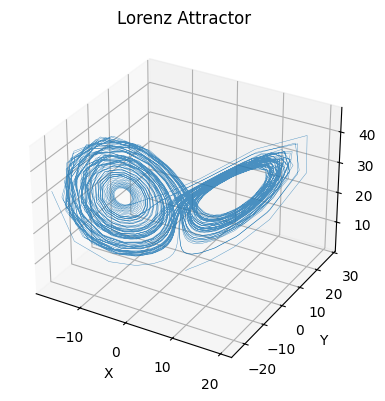

In [3]:
# attractor plot
fig = plt.figure(figsize=(6, 4))
ax  = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, lw=0.3, alpha=0.8)
ax.set_title('Lorenz Attractor')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.tight_layout()
plt.show()

## 2. Data Generation

We sample anchor points from a long trajectory on the attractor and launch short,
randomly perturbed trajectories from each one.  All three components are stored.

In [4]:
# simulate a long trajectory to sample the attractor
sigma, rho, beta = 10.0, 28.0, 8.0 / 3
z0      = [1.0, 1.0, 1.0]
long_t  = np.linspace(0, 100, 10001)
long_sol = solve_ivp(lorenz63, [0, 100], z0, args=(sigma, rho, beta), t_eval=long_t)
trajectory = long_sol.y.T  # shape (10001, 3)

# sample anchor points on the attractor (skip transient)
num_anchors   = 100
anchor_indices = np.linspace(1000, 9000, num_anchors, dtype=int)
anchor_points  = trajectory[anchor_indices]  # shape (num_anchors, 3)

# data generation parameters
perturbN = 10      # perturbations per anchor
sampleN  = 20      # number of time steps to record
tEnd     = 2.0     # short integration window
tSample  = np.linspace(0, tEnd, sampleN + 1)

data = np.zeros((num_anchors * perturbN, 3, sampleN + 1))  # (ntraj, dim, nsteps)

for i, anchor in enumerate(anchor_points):
    for j in range(perturbN):
        IC = anchor + np.sqrt(0.01) * np.random.randn(3)
        sol = solve_ivp(lorenz63, [0, tEnd], IC, args=(sigma, rho, beta), t_eval=tSample)
        data[i * perturbN + j, :, :] = sol.y  # sol.y: (3, nsteps)

In [5]:
print('Data shape:')
print(data.shape)
print('(ntraj, dim, nsteps)')
ntraj, dim, nsteps = data.shape

Data shape:
(1000, 3, 21)
(ntraj, dim, nsteps)


## 3. One-Step Maps

We visualise the scatter plot $u[t=i] \to u[t=i+1]$ for each component.

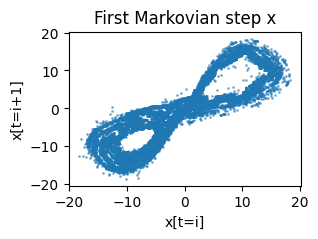

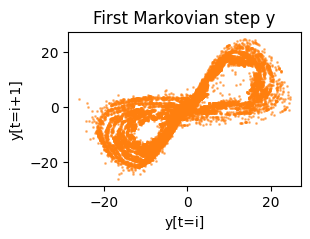

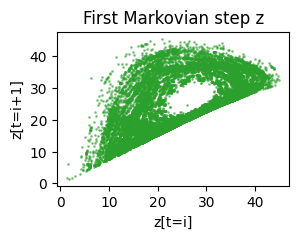

In [6]:
plt.figure(figsize=(3, 2))
for i in range(nsteps-1):
    plt.scatter(data[:, 0, i], data[:, 0, i+1], color='C0', s=1, alpha=0.5)
plt.title('First Markovian step x')
plt.xlabel('x[t=i]')
plt.ylabel('x[t=i+1]')
plt.show()

plt.figure(figsize=(3, 2))
for i in range(nsteps-1):
    plt.scatter(data[:, 1, i], data[:, 1, i+1], color='C1', s=1, alpha=0.5)
plt.title('First Markovian step y')
plt.xlabel('y[t=i]')
plt.ylabel('y[t=i+1]')
plt.show()

plt.figure(figsize=(3, 2))
for i in range(nsteps-1):
    plt.scatter(data[:, 2, i], data[:, 2, i+1], color='C2', s=1, alpha=0.5)
plt.title('First Markovian step z')
plt.xlabel('z[t=i]')
plt.ylabel('z[t=i+1]')
plt.show()

---
## Exercise - Mori–Zwanzig with Neural Network Operators

**Goal**: apply the MZ sequential regression framework to Lorenz 63,
using an MLP as the function approximator.

**Setup**: choose **one** observable component ($x$, $y$, or $z$).
The other two are treated as *unresolved*, just as $y$ was hidden in the Van der Pol case.

The MZ ansatz for the chosen component $u$ reads:

$$u_{n+1} \approx \sum_{k=0}^{K-1} \Omega_k^\theta(u_{n-k})$$

**Sequential regression algorithm** (same as for Van der Pol):

| Step $h$ | Residual target | Operator learned |
|----------|----------------|------------------|
| $0$ | $u_1$ | $\Omega_0$: Markovian prediction |
| $1$ | $u_2 - \Omega_0(u_1)$ | $\Omega_1$: first memory correction |
| $h$ | $u_{h+1} - \sum_{k<h}\Omega_k(u_{h-k})$ | $\Omega_h$ |


In [7]:
# === CHOOSE YOUR OBSERVABLE COMPONENT ===
# 0 -> x(t),  1 -> y(t),  2 -> z(t)
OBS_DIM = 0

DIM_NAMES = ['x', 'y', 'z']
obs_name  = DIM_NAMES[OBS_DIM]
print(f'Observed variable : {obs_name}(t)')
print(f'Latent variables  : {[n for i, n in enumerate(DIM_NAMES) if i != OBS_DIM]}')

Observed variable : x(t)
Latent variables  : ['y', 'z']


### Extract 1D data for the observed component

data_1d shape: (1000, 21):  (1000 trajectories, 21 time steps)


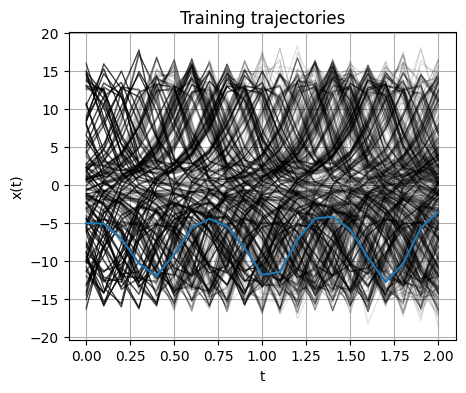

In [8]:
# data has shape (ntraj, 3, nsteps); pick the chosen component
data_1d = data[:, OBS_DIM, :]   # shape: (ntraj, nsteps)
print(f'data_1d shape: {data_1d.shape}:  ({ntraj} trajectories, {nsteps} time steps)')

# quick visual check
plt.figure(figsize=(5, 4))
for i in range(ntraj):
    plt.plot(tSample, data_1d[i], 'k-', alpha=0.15, lw=0.7)

plt.plot(tSample, data_1d[0], 'C0')

plt.xlabel('t')
plt.ylabel(f'{obs_name}(t)')
plt.title(f'Training trajectories')
plt.grid(True)
plt.show()

In [9]:
# Train NN to learn the MZ operator for the observed variable